In [100]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

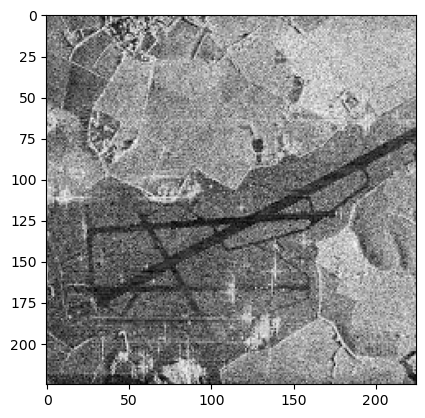

In [116]:
image = cv2.imread('sar_3.jpg')
image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR) 
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 
plt.imshow(image_gray, cmap="gray")

In [117]:
canny = cv2.Canny(image_gray, 150, 350, apertureSize = 3)

In [121]:
lines = cv2.HoughLines(canny, 1, np.pi / 180, 130)

In [123]:
import math 

if lines is not None:
        for i in range(0, len(lines)):
            rho = lines[i][0][0]
            theta = lines[i][0][1]
            a = math.cos(theta)
            b = math.sin(theta)
            x0 = a * rho
            y0 = b * rho
            pt1 = (int(x0 + 1000*(-b)), int(y0 + 1000*(a)))
            pt2 = (int(x0 - 1000*(-b)), int(y0 - 1000*(a)))
            cv2.line(image, pt1, pt2, (0,0,255), 3, cv2.LINE_AA)

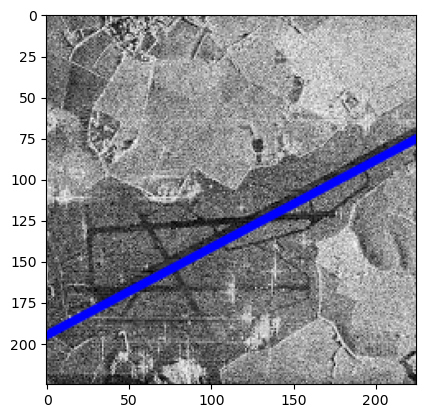

In [124]:
plt.imshow(image)

# Точечная бинаризация

In [52]:
import copy

bin_img = copy.deepcopy(image_gray)
T = 50
bin_img[image_gray < T] = 0
bin_img[image_gray >= T] = 255

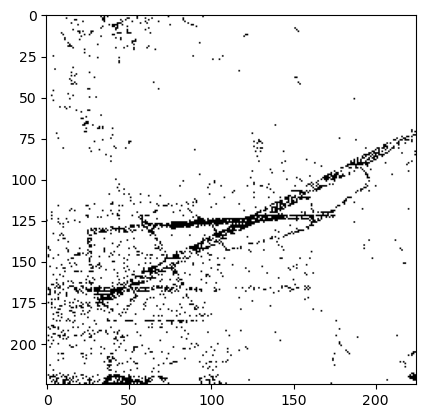

In [53]:
plt.imshow(bin_img, cmap="gray")

# Бинаризация Отсу

In [45]:
_,th2 = cv2.threshold(image_gray,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)

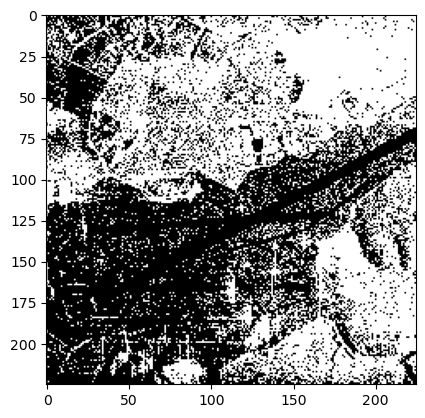

In [46]:
plt.imshow(th2, cmap="gray")

# Адаптивная бинаризация

In [50]:
th3 = cv2.adaptiveThreshold(image_gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 71, 21)

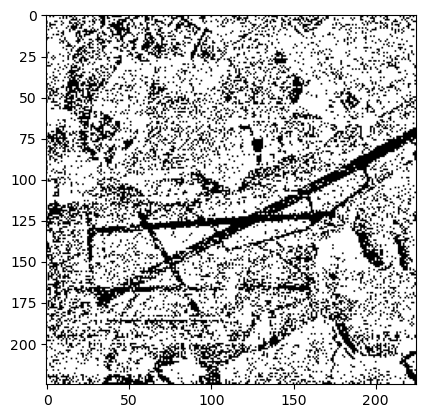

In [51]:
plt.imshow(th3, cmap="gray")

# Вывод
Лучший результат показала точечная бинаризация, полоса отображается чётче всего, с минимумом шума. Адаптивная бинаризация дала средний результат — полоса видна, но вместе с заметным шумом текстуры местности.